In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

df= pd.read_csv(r"D:\Data Analyst Exercise\superstore-sales-analysis\dataset\processed\superstore_cleaned.csv",encoding='latin1')

# Return date columns to datetime format
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])   
print("Dataset shape: ",df.shape)

df.head()

Matplotlib is building the font cache; this may take a moment.


Dataset shape:  (9994, 22)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Duration
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7


In [4]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()
total_quantity = df['Quantity'].sum()

average_order_value = total_sales / total_orders
profit_margin = total_profit / total_sales * 100

print("===== BUSINESS PERFORMANCE =====")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Customers: {total_customers}")
print(f"Total Quantity: {total_quantity}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")

===== BUSINESS PERFORMANCE =====
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5009
Total Customers: 793
Total Quantity: 37873
Average Order Value: $458.61
Profit Margin: 12.47%


In [5]:
print("First Order Date: ",df['Order Date'].min())
print("Last Order Date: ",df['Order Date'].max())  


First Order Date:  2014-01-03 00:00:00
Last Order Date:  2017-12-30 00:00:00


In [6]:
monthly_sales = (df.groupby(df['Order Date'].dt.to_period('M'))['Sales']
                .sum().reset_index())

monthly_sales['Order Date'] = monthly_sales['Order Date'].dt.to_timestamp()

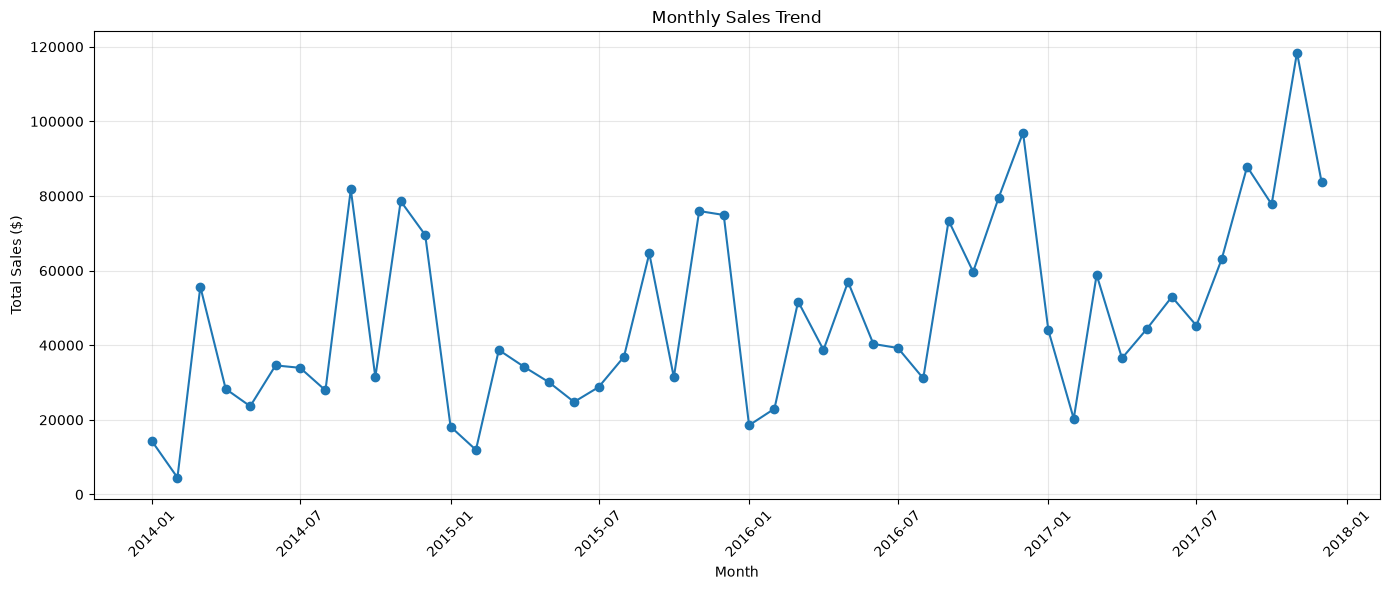

In [7]:
plt.figure(figsize=(14, 6))
plt.plot(monthly_sales['Order Date'], monthly_sales['Sales'], marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Months with highest sales 
highest_month = monthly_sales.loc[monthly_sales['Sales'].idxmax()]

# Months with lowest sales
lowest_month = monthly_sales.loc[monthly_sales['Sales'].idxmin()]

print("HIGHEST MONTHLY SALES")
print(highest_month)

print("\nLOWEST MONTHLY SALES")
print(lowest_month)

HIGHEST MONTHLY SALES
Order Date    2017-11-01 00:00:00
Sales                  118447.825
Name: 46, dtype: object

LOWEST MONTHLY SALES
Order Date    2014-02-01 00:00:00
Sales                    4519.892
Name: 1, dtype: object


In [9]:
yearly_sales = (
    df.groupby(df['Order Date'].dt.year)
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique')
    )
    .reset_index()
)

yearly_sales.rename(
    columns={'Order Date': 'Year'},
    inplace=True
)

yearly_sales['Sales Growth (%)'] = (
    yearly_sales['Total_Sales'].pct_change() * 100
)

yearly_sales

C:\Users\hilmy\AppData\Local\Temp\ipykernel_4016\52307472.py:11: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  yearly_sales.rename(


,Year,Total_Sales,Total_Profit,Total_Orders,Sales Growth (%)
0,2014,484247.4981,49543.9741,969,NaN
1,2015,470532.5090,61618.6037,1038,-2.832227
2,2016,609205.5980,81795.1743,1315,29.471521
3,2017,733215.2552,93439.2696,1687,20.355962


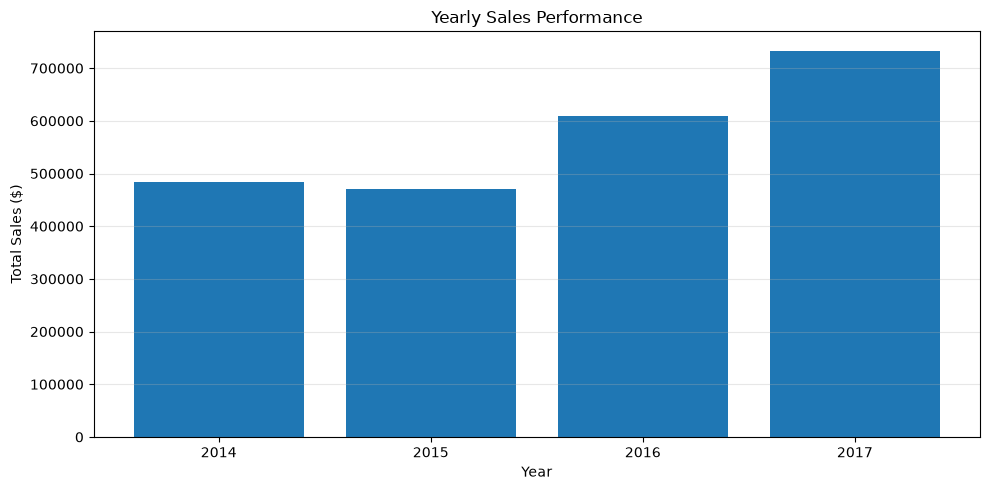

In [10]:
plt.figure(figsize=(10, 5))
plt.bar(yearly_sales['Year'].astype(str), yearly_sales['Total_Sales'])
plt.title('Yearly Sales Performance')
plt.xlabel('Year')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Calculate profit margin for each year
yearly_sales['Profit_Margin (%)'] = (
    yearly_sales['Total_Profit'] /
    yearly_sales['Total_Sales'] * 100
)

yearly_sales

,Year,Total_Sales,Total_Profit,Total_Orders,Sales Growth (%),Profit_Margin (%)
0,2014,484247.4981,49543.9741,969,NaN,10.231126
1,2015,470532.5090,61618.6037,1038,-2.832227,13.095504
2,2016,609205.5980,81795.1743,1315,29.471521,13.426530
3,2017,733215.2552,93439.2696,1687,20.355962,12.743771


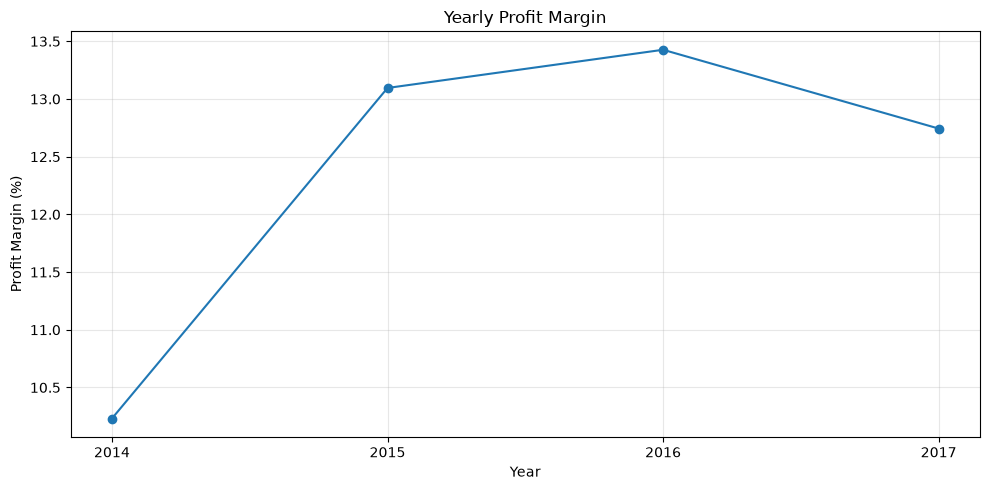

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_sales['Year'],
    yearly_sales['Profit_Margin (%)'],
    marker='o'
)

plt.title('Yearly Profit Margin')
plt.xlabel('Year')
plt.ylabel('Profit Margin (%)')
plt.xticks(yearly_sales['Year'])
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
category_analysis = (
    df.groupby('Category')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Quantity=('Quantity', 'sum')
    )
    .reset_index()
)

category_analysis = category_analysis.sort_values(
    by='Total_Sales',
    ascending=False
)

category_analysis

,Category,Total_Sales,Total_Profit,Total_Quantity
2,Technology,836154.0330,145454.9481,6939
0,Furniture,741999.7953,18451.2728,8028
1,Office Supplies,719047.0320,122490.8008,22906


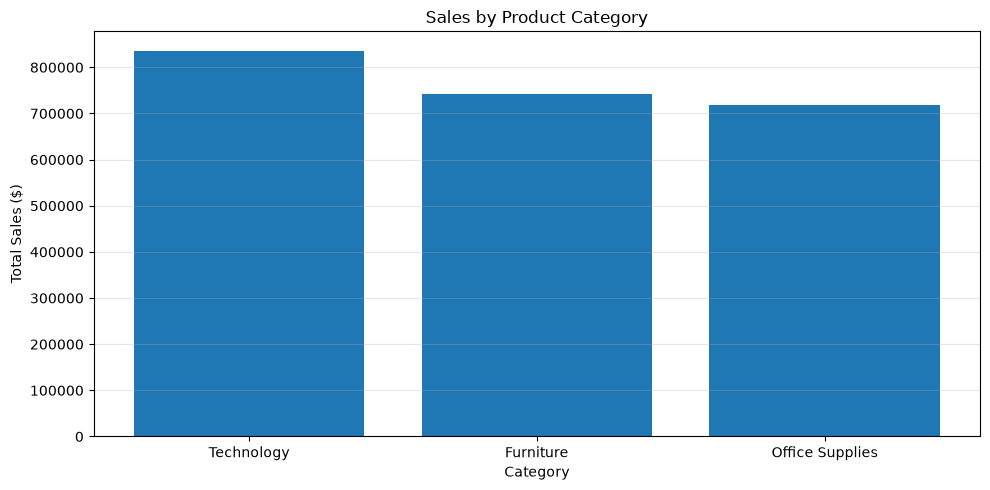

In [14]:
plt.figure(figsize=(10, 5))

plt.bar(
    category_analysis['Category'],
    category_analysis['Total_Sales']
)

plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

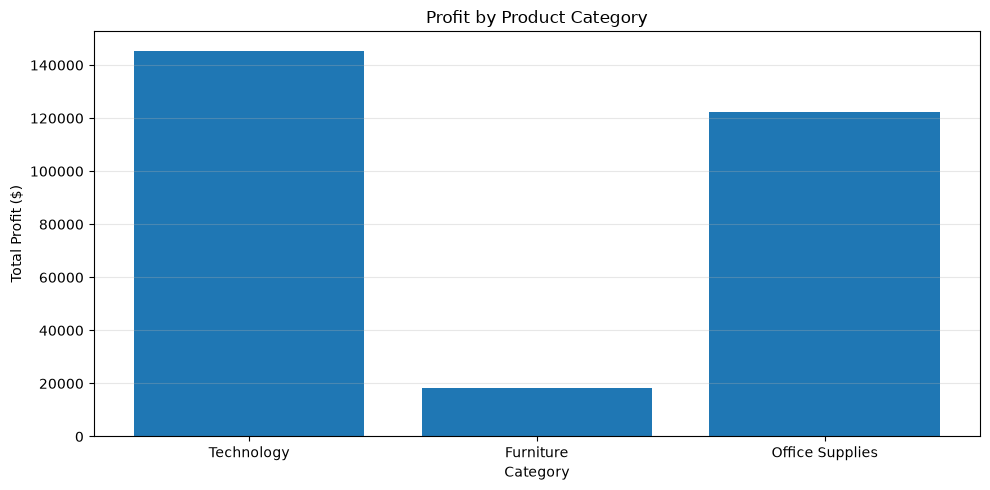

In [15]:
plt.figure(figsize=(10, 5))

plt.bar(
    category_analysis['Category'],
    category_analysis['Total_Profit']
)

plt.title('Profit by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Profit ($)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
subcategory_analysis = (
    df.groupby(['Category', 'Sub-Category'])
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Quantity=('Quantity', 'sum')
    )
    .reset_index()
)

# Calculate profit margin for each sub-category
subcategory_analysis['Profit_Margin (%)'] = (
    subcategory_analysis['Total_Profit'] /
    subcategory_analysis['Total_Sales'] * 100
)

# Sort subcategory_analysis by Total_Profit in descending order
subcategory_analysis = subcategory_analysis.sort_values(
    by='Total_Profit',
    ascending=False
)

subcategory_analysis

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin (%)
14,Technology,Copiers,149528.0300,55617.8249,234,37.195585
16,Technology,Phones,330007.0540,44515.7306,3289,13.489327
13,Technology,Accessories,167380.3180,41936.6357,2976,25.054700
10,Office Supplies,Paper,78479.2060,34053.5693,5178,43.391837
6,Office Supplies,Binders,203412.7330,30221.7633,5974,14.857361
1,Furniture,Chairs,328449.1030,26590.1663,2356,8.095673
11,Office Supplies,Storage,223843.6080,21278.8264,3158,9.506113
4,Office Supplies,Appliances,107532.1610,18138.0054,1729,16.867517
2,Furniture,Furnishings,91705.1640,13059.1436,3563,14.240358
7,Office Supplies,Envelopes,16476.4020,6964.1767,906,42.267582


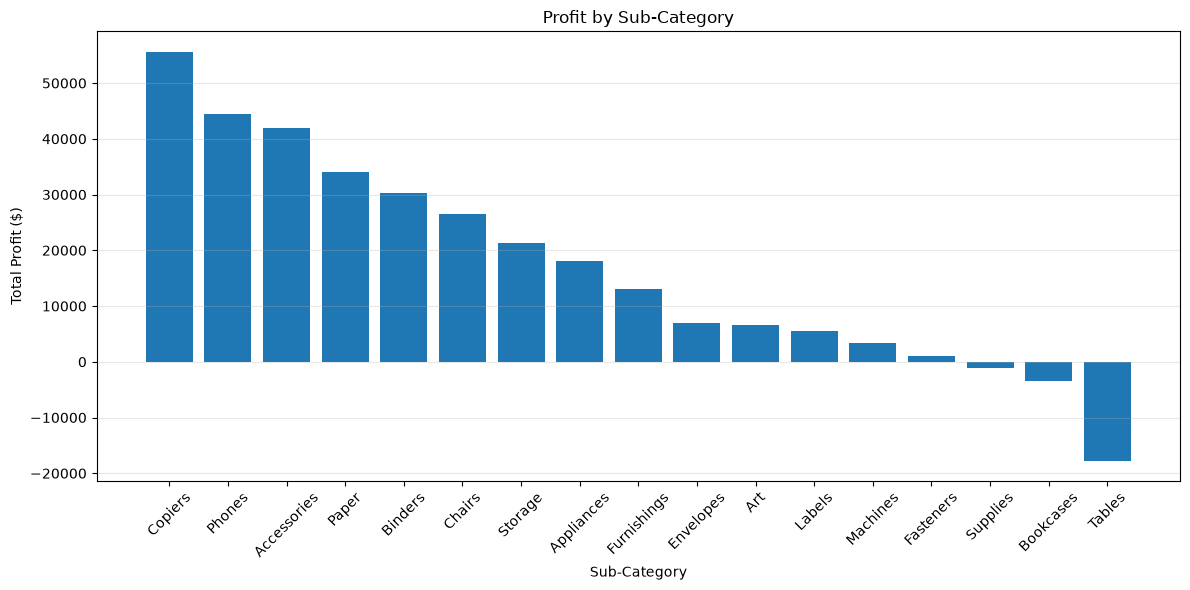

In [17]:
plt.figure(figsize=(12, 6))

plt.bar(
    subcategory_analysis['Sub-Category'],
    subcategory_analysis['Total_Profit']
)

plt.title('Profit by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Total Profit ($)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

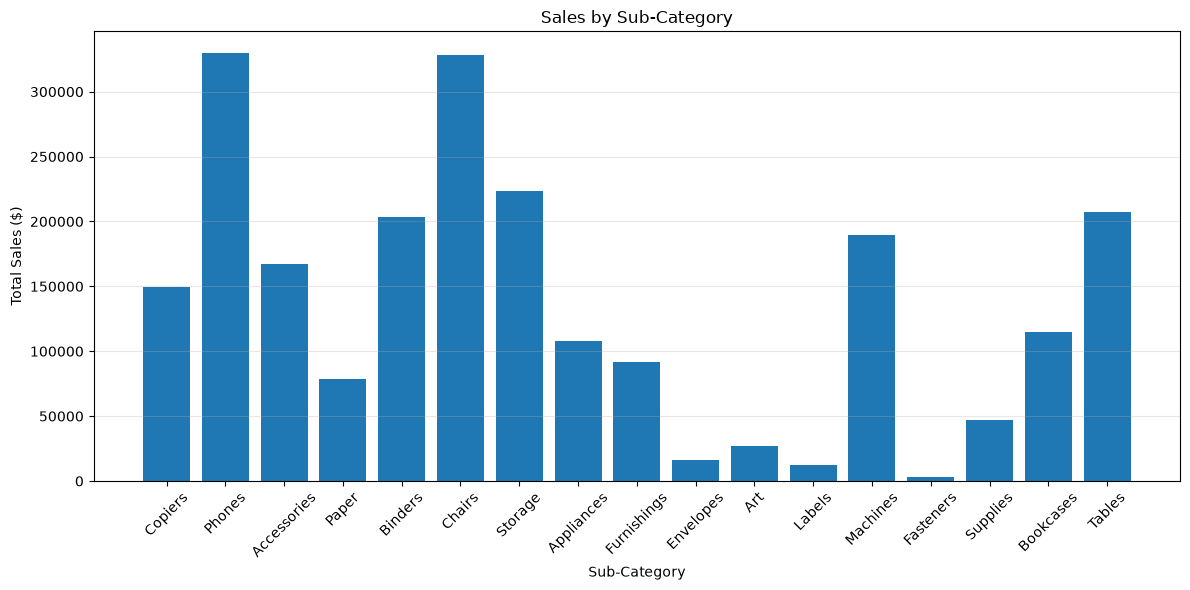

In [18]:
plt.figure(figsize=(12, 6))

plt.bar(
    subcategory_analysis['Sub-Category'],
    subcategory_analysis['Total_Sales']
)

plt.title('Sales by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# Choose subcategories with negative profit
problem_subcategories = [
    'Tables',
    'Bookcases',
    'Supplies'
]

# Filter data
problem_data = df[
    df['Sub-Category'].isin(problem_subcategories)
]

# Analyze the impact of discount on sales and profit for the problem subcategories
discount_analysis = (
    problem_data.groupby(
        ['Sub-Category', 'Discount']
    )
    .agg(
        Total_Transactions=('Row ID', 'count'),
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Average_Profit=('Profit', 'mean')
    )
    .reset_index()
    .sort_values(['Sub-Category', 'Discount'])
)

discount_analysis

,Sub-Category,Discount,Total_Transactions,Total_Sales,Total_Profit,Average_Profit
0,Bookcases,0.00,60,31935.9800,6075.7117,101.261862
1,Bookcases,0.15,52,27558.5215,1418.9915,27.288298
2,Bookcases,0.20,46,26841.4960,130.5022,2.837004
3,Bookcases,0.30,10,4282.6980,-555.8726,-55.587260
4,Bookcases,0.32,27,14493.4588,-2391.1377,-88.560656
5,Bookcases,0.50,18,7308.4600,-4255.8117,-236.433983
6,Bookcases,0.70,15,2459.3820,-3894.9394,-259.662627
7,Supplies,0.00,117,31559.2100,1718.3942,14.687130
8,Supplies,0.20,73,15114.3280,-2907.4937,-39.828681
9,Tables,0.00,72,71578.7600,13276.2997,184.393051


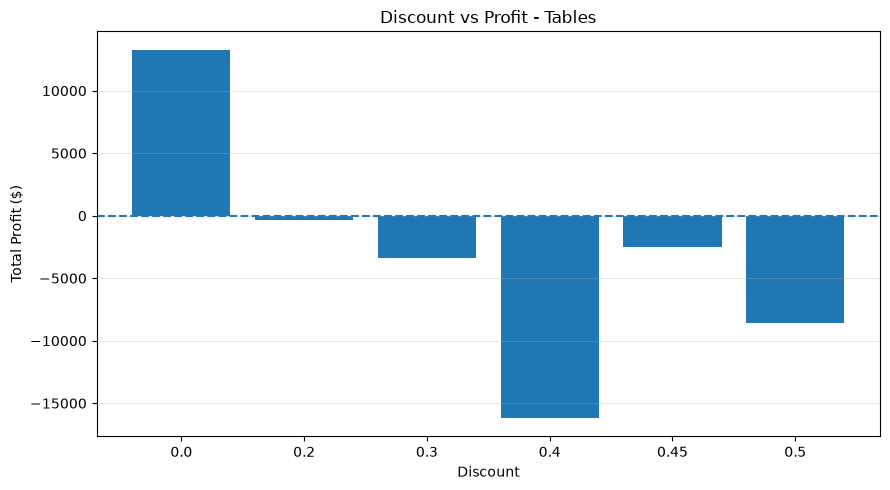

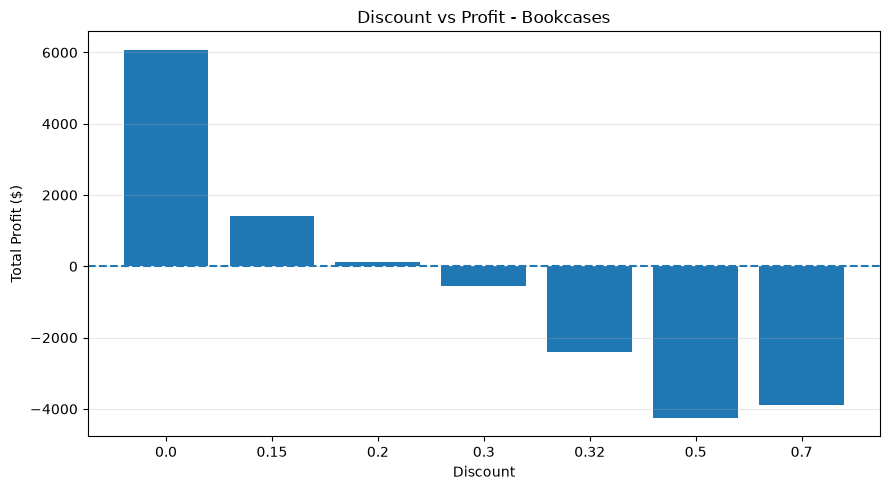

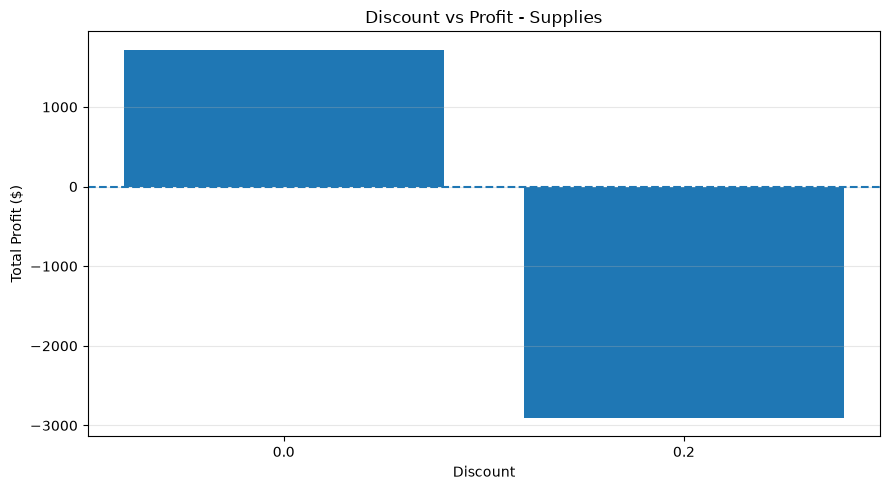

In [20]:
for category in problem_subcategories:

    temp = discount_analysis[
        discount_analysis['Sub-Category'] == category
    ]

    plt.figure(figsize=(9, 5))

    plt.bar(
        temp['Discount'].astype(str),
        temp['Total_Profit']
    )

    plt.axhline(y=0, linestyle='--')

    plt.title(f'Discount vs Profit - {category}')
    plt.xlabel('Discount')
    plt.ylabel('Total Profit ($)')
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

In [21]:
discount_comparison = (
    df.groupby(['Sub-Category', 'Discount'])
    .agg(
        Total_Transactions=('Row ID', 'count'),
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Average_Profit=('Profit', 'mean')
    )
    .reset_index()
)

discount_comparison = discount_comparison.sort_values(
    by=['Sub-Category', 'Discount']
)

discount_comparison.head(20)

,Sub-Category,Discount,Total_Transactions,Total_Sales,Total_Profit,Average_Profit
0,Accessories,0.00,471,118370.3100,35289.2539,74.924106
1,Accessories,0.20,304,49010.0080,6647.3818,21.866388
2,Appliances,0.00,271,78066.1900,23183.7361,85.548842
3,Appliances,0.10,16,4324.1490,1086.0808,67.880050
4,Appliances,0.20,112,21759.2880,2497.8297,22.302051
5,Appliances,0.80,67,3382.5340,-8629.6412,-128.800615
6,Art,0.00,498,18014.6400,5380.6006,10.804419
7,Art,0.20,298,9104.1520,1147.1864,3.849619
8,Binders,0.00,337,81829.4800,39314.4507,116.660091
9,Binders,0.20,573,85442.6400,29417.8090,51.339981


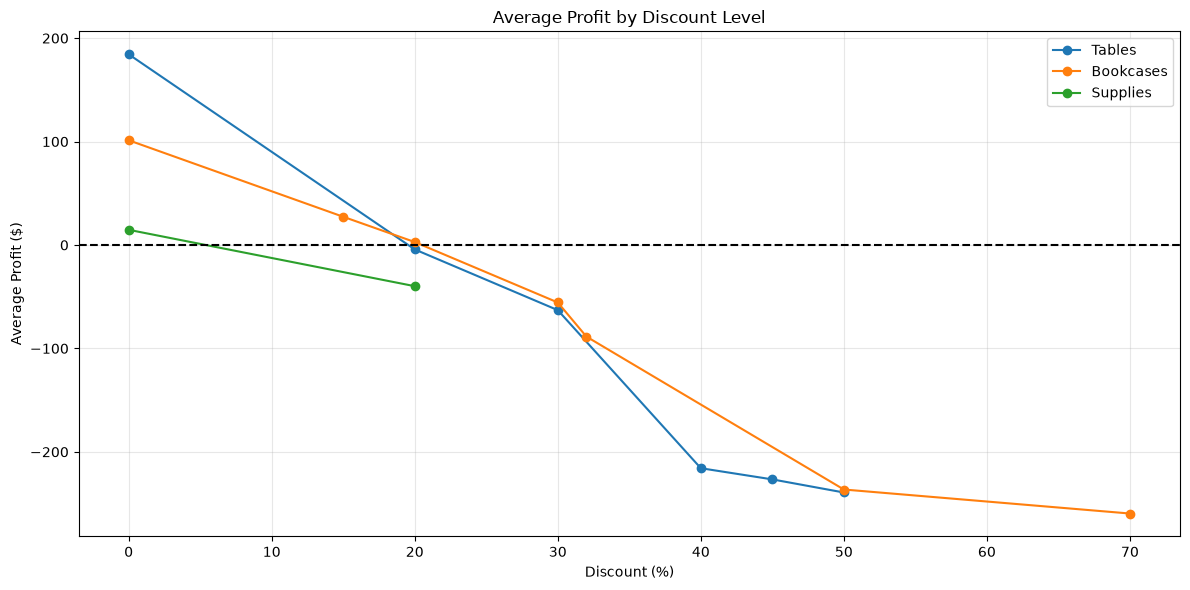

In [22]:
plt.figure(figsize=(12, 6))

for category in problem_subcategories:

    temp = discount_comparison[
        discount_comparison['Sub-Category'] == category
    ]

    plt.plot(
        temp['Discount'] * 100,
        temp['Average_Profit'],
        marker='o',
        label=category
    )

plt.axhline(y=0, linestyle='--', color='black')

plt.title('Average Profit by Discount Level')
plt.xlabel('Discount (%)')
plt.ylabel('Average Profit ($)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
regional_analysis = (
    df.groupby('Region')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
    .reset_index()
)

# Menghitung profit margin
regional_analysis['Profit_Margin (%)'] = (
    regional_analysis['Total_Profit'] /
    regional_analysis['Total_Sales'] * 100
)

regional_analysis = regional_analysis.sort_values(
    by='Total_Sales',
    ascending=False
)

regional_analysis

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin (%)
3,West,725457.8245,108418.4489,1611,12266,14.944831
1,East,678781.2400,91522.7800,1401,10618,13.483399
0,Central,501239.8908,39706.3625,1175,8780,7.921629
2,South,391721.9050,46749.4303,822,6209,11.934342


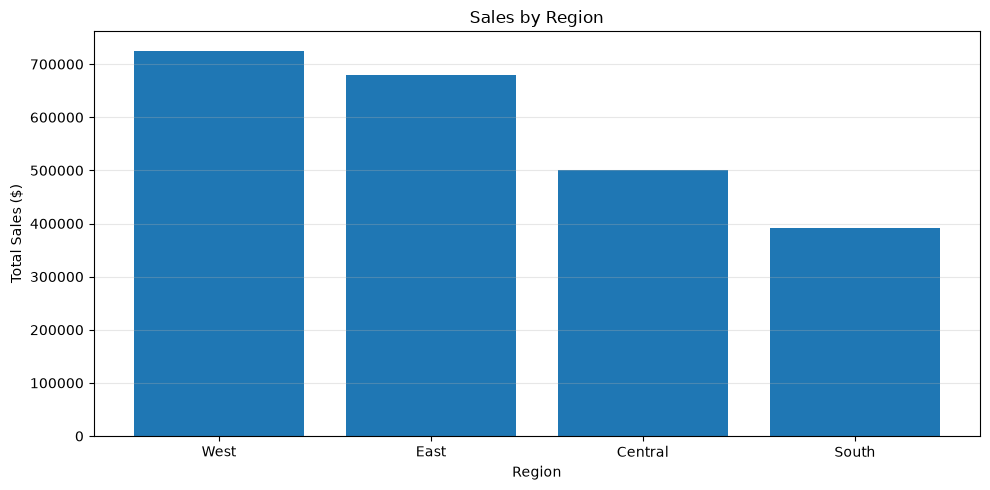

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    regional_analysis['Region'],
    regional_analysis['Total_Sales']
)

plt.title('Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

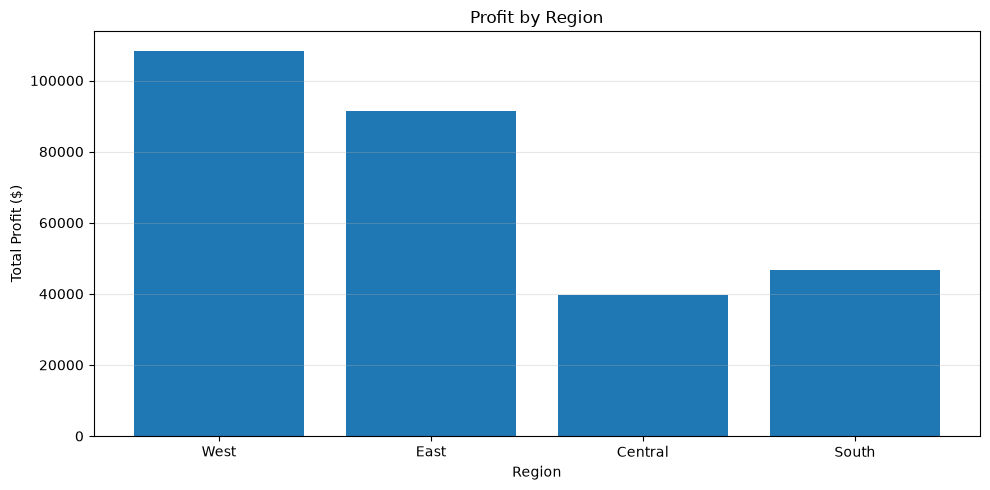

In [25]:
plt.figure(figsize=(10, 5))

plt.bar(
    regional_analysis['Region'],
    regional_analysis['Total_Profit']
)

plt.title('Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit ($)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

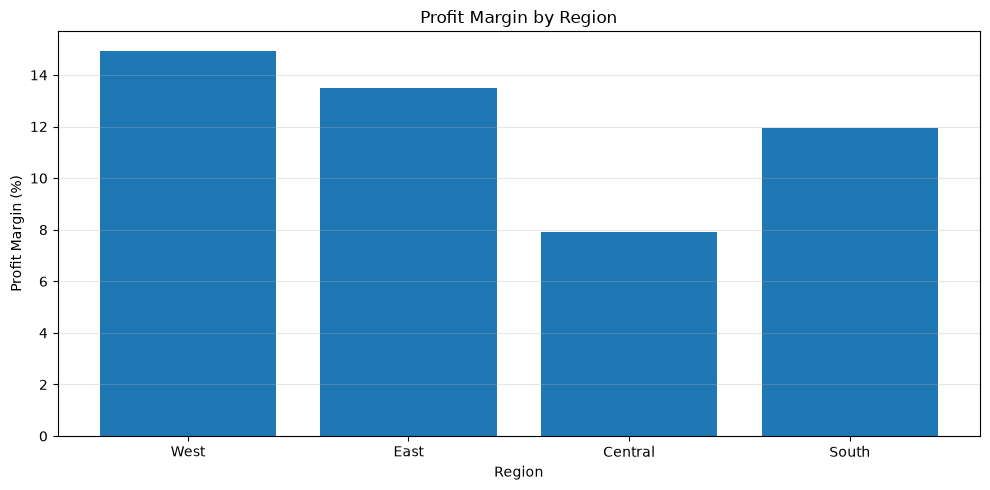

In [26]:
plt.figure(figsize=(10, 5))

plt.bar(
    regional_analysis['Region'],
    regional_analysis['Profit_Margin (%)']
)

plt.title('Profit Margin by Region')
plt.xlabel('Region')
plt.ylabel('Profit Margin (%)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
regional_category = (
    df.groupby(['Region', 'Category'])
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Quantity=('Quantity', 'sum')
    )
    .reset_index()
)

regional_category['Profit_Margin (%)'] = (
    regional_category['Total_Profit'] /
    regional_category['Total_Sales'] * 100
)

regional_category.sort_values(
    by=['Region', 'Total_Sales'],
    ascending=[True, False]
)

,Region,Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin (%)
2,Central,Technology,170416.3120,33697.4320,1544,19.773595
1,Central,Office Supplies,167026.4150,8879.9799,5409,5.316512
0,Central,Furniture,163797.1638,-2871.0494,1827,-1.752808
5,East,Technology,264973.9810,47462.0351,1942,17.911961
3,East,Furniture,208291.2040,3046.1658,2214,1.462455
4,East,Office Supplies,205516.0550,41014.5791,6462,19.956873
8,South,Technology,148771.9080,19991.8314,1118,13.437908
7,South,Office Supplies,125651.3130,19986.3928,3800,15.906235
6,South,Furniture,117298.6840,6771.2061,1291,5.772619
9,West,Furniture,252612.7435,11504.9503,2696,4.554382


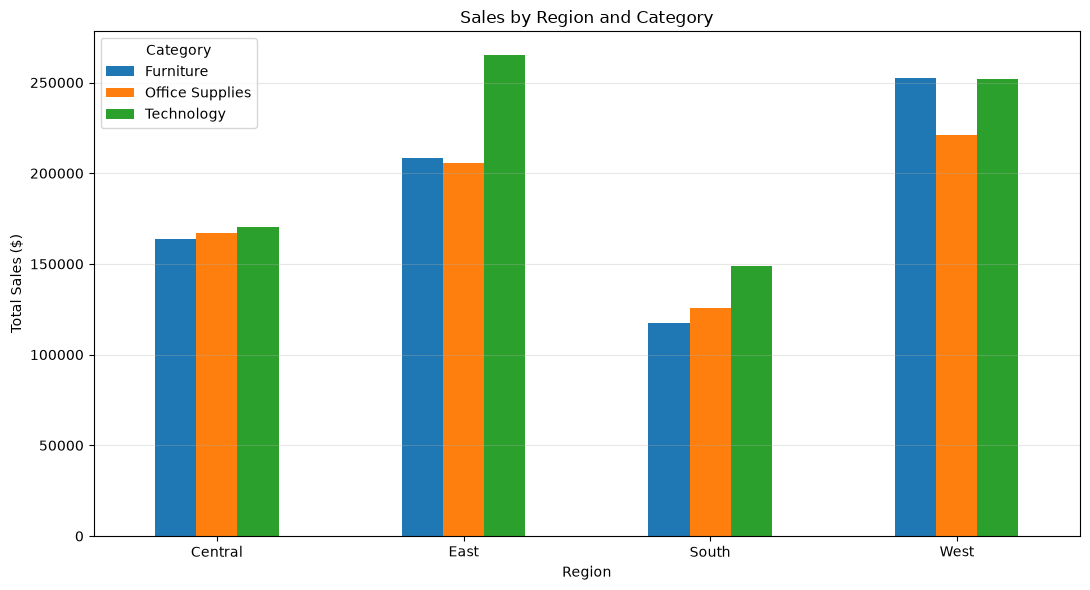

In [28]:
sales_pivot = regional_category.pivot(
    index='Region',
    columns='Category',
    values='Total_Sales'
)

sales_pivot.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Sales by Region and Category')
plt.xlabel('Region')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Category')

plt.tight_layout()
plt.show()

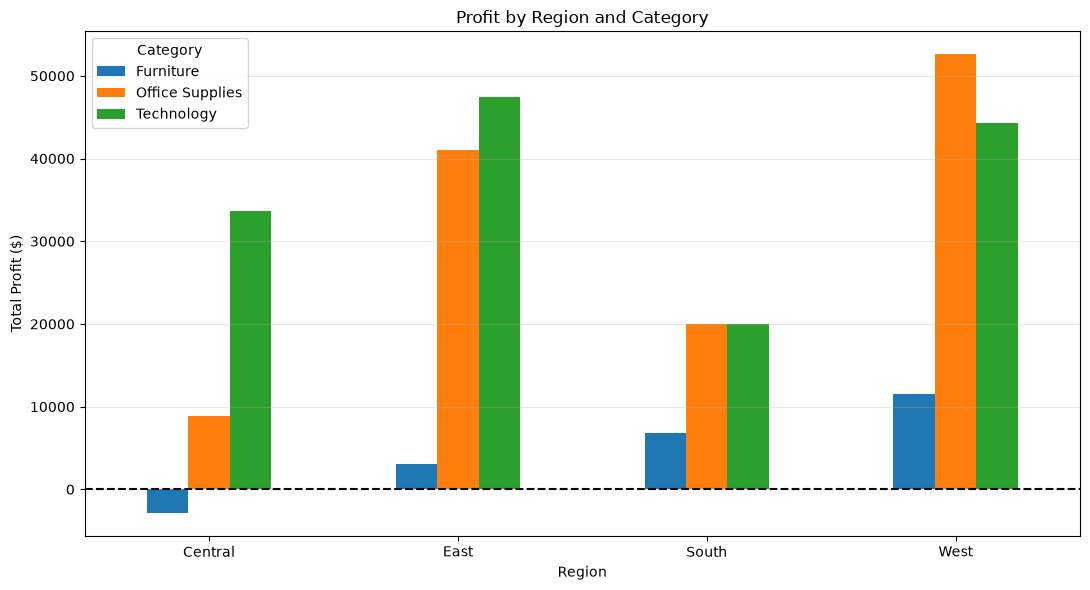

In [29]:
profit_pivot = regional_category.pivot(
    index='Region',
    columns='Category',
    values='Total_Profit'
)

profit_pivot.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Profit by Region and Category')
plt.xlabel('Region')
plt.ylabel('Total Profit ($)')
plt.xticks(rotation=0)
plt.axhline(y=0, color='black', linestyle='--')
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Category')

plt.tight_layout()
plt.show()

In [31]:
central_analysis = regional_category[
    regional_category['Region'] == 'Central'
].sort_values(
    by='Total_Profit'
)

central_analysis

,Region,Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin (%)
0,Central,Furniture,163797.1638,-2871.0494,1827,-1.752808
1,Central,Office Supplies,167026.4150,8879.9799,5409,5.316512
2,Central,Technology,170416.3120,33697.4320,1544,19.773595


In [32]:
central_subcategory = (
    df[df['Region'] == 'Central']
    .groupby(['Category', 'Sub-Category'])
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Quantity=('Quantity', 'sum')
    )
    .reset_index()
)

central_subcategory['Profit_Margin (%)'] = (
    central_subcategory['Total_Profit'] /
    central_subcategory['Total_Sales'] * 100
)

central_subcategory = central_subcategory.sort_values(
    by='Total_Profit',
    ascending=True
)

central_subcategory

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin (%)
2,Furniture,Furnishings,15254.3700,-3906.2168,758,-25.607198
3,Furniture,Tables,39154.9710,-3559.6504,262,-9.091184
4,Office Supplies,Appliances,23582.0330,-2638.6175,470,-11.189101
0,Furniture,Bookcases,24157.1768,-1997.9043,192,-8.270438
15,Technology,Machines,26797.3840,-1486.0666,66,-5.545566
6,Office Supplies,Binders,56923.2820,-1043.6369,1473,-1.833410
12,Office Supplies,Supplies,9467.3720,-661.8881,122,-6.991255
8,Office Supplies,Fasteners,778.0300,236.6186,227,30.412529
9,Office Supplies,Labels,2451.4720,1073.0794,284,43.772860
5,Office Supplies,Art,5765.3400,1195.1591,678,20.730071


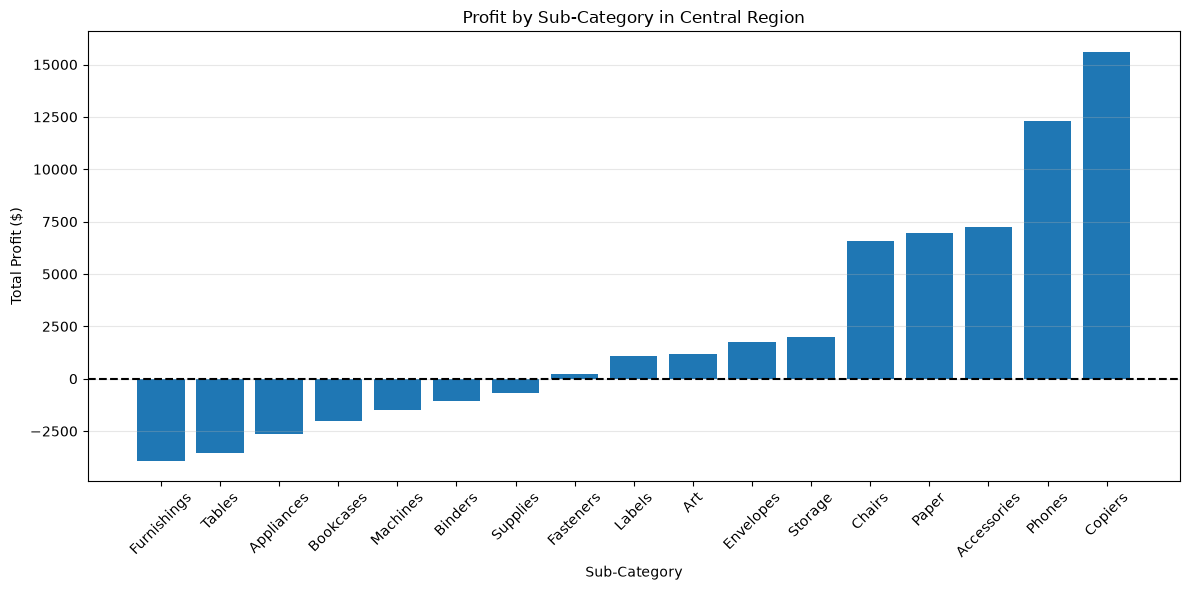

In [33]:
plt.figure(figsize=(12, 6))

plt.bar(
    central_subcategory['Sub-Category'],
    central_subcategory['Total_Profit']
)

plt.axhline(y=0, color='black', linestyle='--')

plt.title('Profit by Sub-Category in Central Region')
plt.xlabel('Sub-Category')
plt.ylabel('Total Profit ($)')
plt.xticks(rotation=45)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
central_furniture = central_subcategory[
    central_subcategory['Category'] == 'Furniture'
]

central_furniture

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin (%)
2,Furniture,Furnishings,15254.3700,-3906.2168,758,-25.607198
3,Furniture,Tables,39154.9710,-3559.6504,262,-9.091184
0,Furniture,Bookcases,24157.1768,-1997.9043,192,-8.270438
1,Furniture,Chairs,85230.6460,6592.7221,615,7.735154


In [35]:
segment_analysis = (
    df.groupby('Segment')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Customers=('Customer ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
    .reset_index()
)

segment_analysis['Profit_Margin (%)'] = (
    segment_analysis['Total_Profit'] /
    segment_analysis['Total_Sales'] * 100
)

segment_analysis = segment_analysis.sort_values(
    by='Total_Sales',
    ascending=False
)

segment_analysis

,Segment,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Total_Quantity,Profit_Margin (%)
0,Consumer,1.161401e+06,134119.2092,2586,409,19521,11.548050
1,Corporate,7.061464e+05,91979.1340,1514,236,11608,13.025506
2,Home Office,4.296531e+05,60298.6785,909,148,6744,14.034269


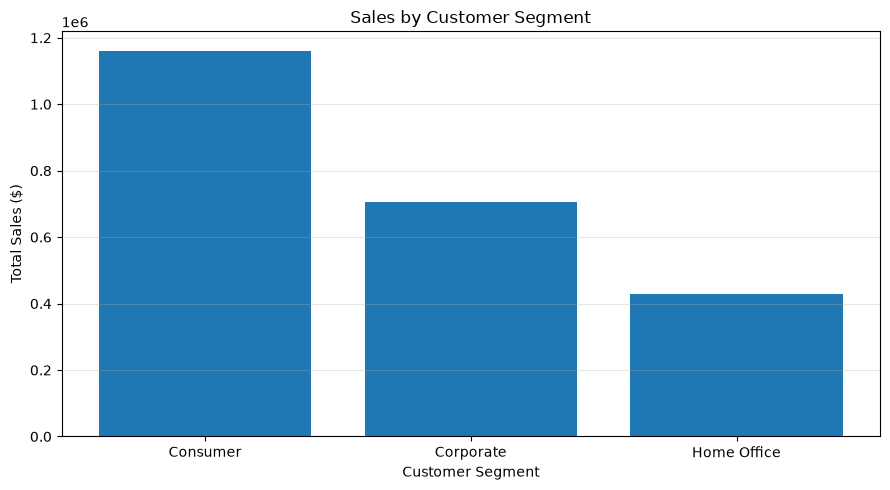

In [36]:
plt.figure(figsize=(9, 5))

plt.bar(
    segment_analysis['Segment'],
    segment_analysis['Total_Sales']
)

plt.title('Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

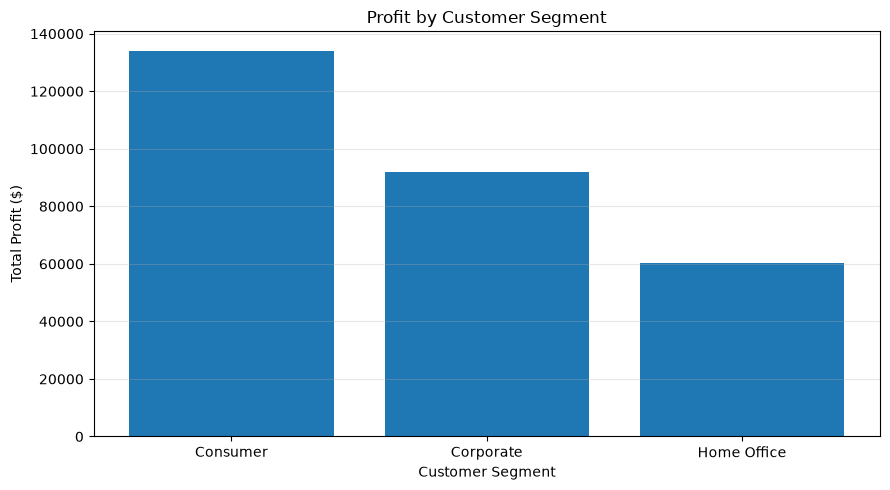

In [37]:
plt.figure(figsize=(9, 5))

plt.bar(
    segment_analysis['Segment'],
    segment_analysis['Total_Profit']
)

plt.title('Profit by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Profit ($)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

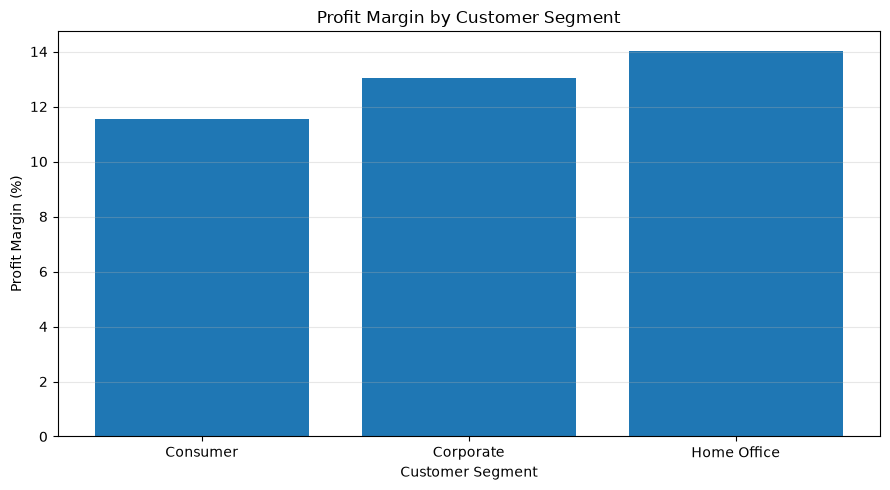

In [38]:
plt.figure(figsize=(9, 5))

plt.bar(
    segment_analysis['Segment'],
    segment_analysis['Profit_Margin (%)']
)

plt.title('Profit Margin by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Profit Margin (%)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
segment_analysis['Average_Order_Value'] = (
    segment_analysis['Total_Sales'] /
    segment_analysis['Total_Orders']
)

segment_analysis[
    ['Segment', 'Average_Order_Value']
]

,Segment,Average_Order_Value
0,Consumer,449.111116
1,Corporate,466.411075
2,Home Office,472.665730


In [40]:
shipping_analysis = (
    df.groupby('Ship Mode')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum'),
        Avg_Shipping_Duration=('Shipping Duration', 'mean')
    )
    .reset_index()
)

shipping_analysis['Profit_Margin (%)'] = (
    shipping_analysis['Total_Profit'] /
    shipping_analysis['Total_Sales'] * 100
)

shipping_analysis = shipping_analysis.sort_values(
    by='Total_Sales',
    ascending=False
)

shipping_analysis

,Ship Mode,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Avg_Shipping_Duration,Profit_Margin (%)
3,Standard Class,1.358216e+06,164088.7875,2994,22797,5.006535,12.081202
2,Second Class,4.591936e+05,57446.6354,964,7423,3.238046,12.510331
0,First Class,3.514284e+05,48969.8399,787,5693,2.182705,13.934513
1,Same Day,1.283631e+05,15891.7589,264,1960,0.044199,12.380315


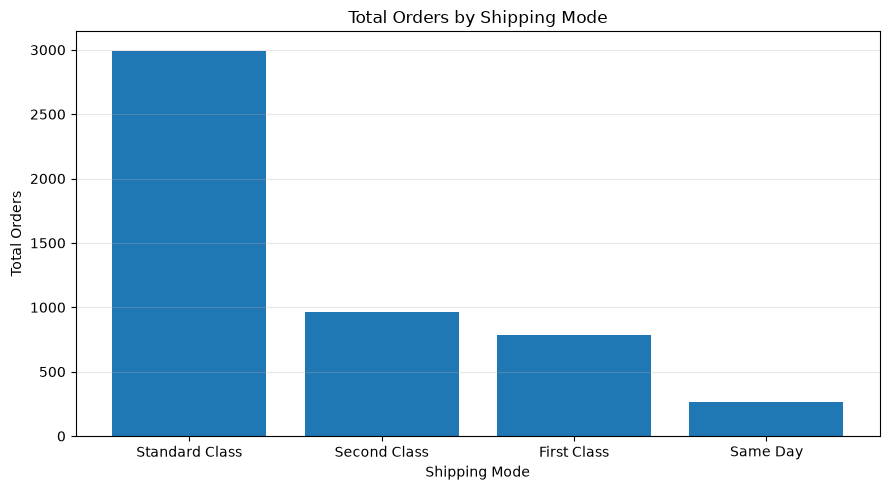

In [41]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_analysis['Ship Mode'],
    shipping_analysis['Total_Orders']
)

plt.title('Total Orders by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Total Orders')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

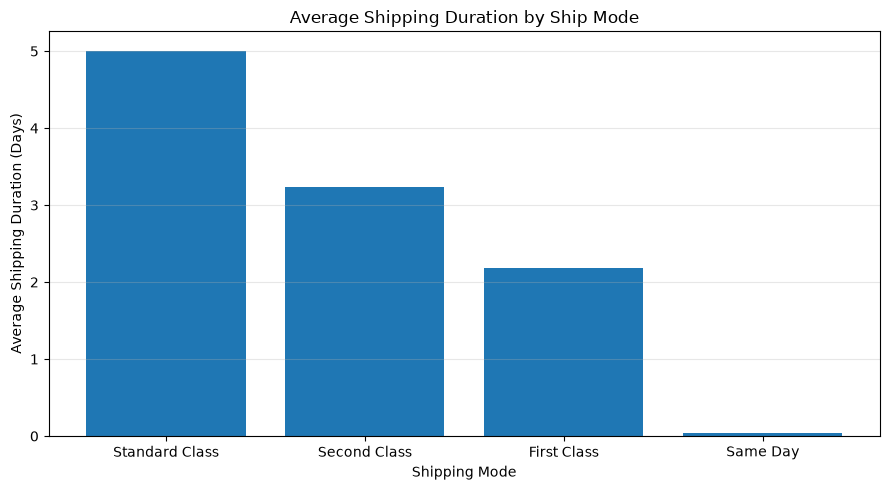

In [42]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_analysis['Ship Mode'],
    shipping_analysis['Avg_Shipping_Duration']
)

plt.title('Average Shipping Duration by Ship Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Average Shipping Duration (Days)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

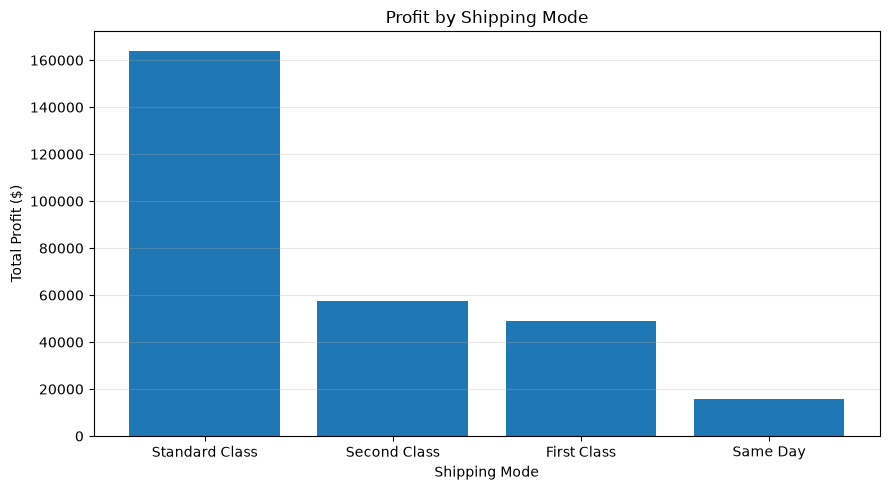

In [43]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_analysis['Ship Mode'],
    shipping_analysis['Total_Profit']
)

plt.title('Profit by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Total Profit ($)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

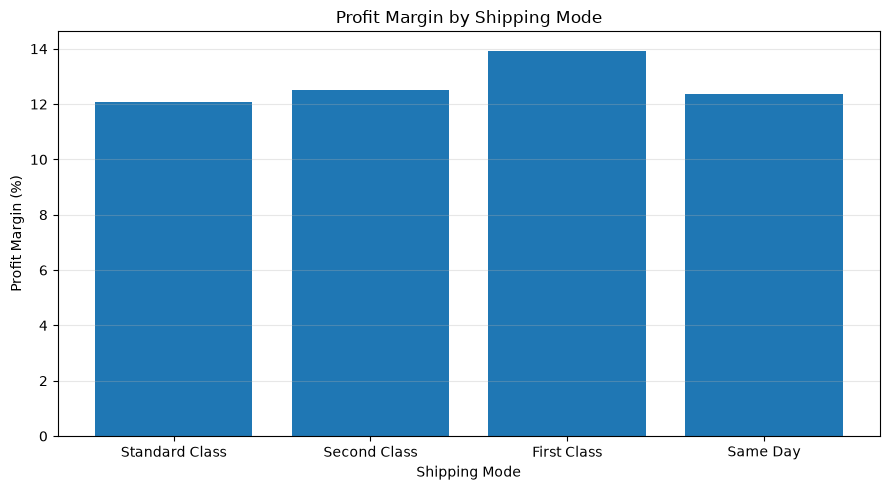

In [44]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_analysis['Ship Mode'],
    shipping_analysis['Profit_Margin (%)']
)

plt.title('Profit Margin by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Profit Margin (%)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
same_day_check = df[
    df['Ship Mode'] == 'Same Day'
].groupby('Shipping Duration').size().reset_index(
    name='Total_Transactions'
)

same_day_check

,Shipping Duration,Total_Transactions
0,0,519
1,1,24


In [47]:
order_shipping = (
    df.groupby('Order ID')
    .agg(
        Ship_Mode=('Ship Mode', 'first'),
        Shipping_Duration=('Shipping Duration', 'first')
    )
    .reset_index()
)

order_shipping.head()

,Order ID,Ship_Mode,Shipping_Duration
0,CA-2014-100006,Standard Class,6
1,CA-2014-100090,Standard Class,4
2,CA-2014-100293,Standard Class,4
3,CA-2014-100328,Standard Class,6
4,CA-2014-100363,Standard Class,7


In [49]:
same_day_orders = order_shipping[
    order_shipping['Ship_Mode'] == 'Same Day'
]

same_day_distribution = (
    same_day_orders['Shipping_Duration']
    .value_counts()
    .sort_index()
    .reset_index()
)

same_day_distribution.columns = [
    'Shipping Duration',
    'Total Orders'
]

same_day_distribution

,Shipping Duration,Total Orders
0,0,252
1,1,12


In [50]:
shipping_duration_order = (
    order_shipping.groupby('Ship_Mode')
    .agg(
        Total_Orders=('Order ID', 'nunique'),
        Avg_Shipping_Duration=('Shipping_Duration', 'mean')
    )
    .reset_index()
)

shipping_duration_order

,Ship_Mode,Total_Orders,Avg_Shipping_Duration
0,First Class,787,2.188056
1,Same Day,264,0.045455
2,Second Class,964,3.232365
3,Standard Class,2994,5.001002


In [51]:
order_validation = df.groupby('Order ID').agg(
    Unique_Ship_Mode=('Ship Mode', 'nunique'),
    Unique_Shipping_Duration=('Shipping Duration', 'nunique')
)

print(
    "Inconsistent Ship Mode:",
    (order_validation['Unique_Ship_Mode'] > 1).sum()
)

print(
    "Inconsistent Shipping Duration:",
    (order_validation['Unique_Shipping_Duration'] > 1).sum()
)

Inconsistent Ship Mode: 0
Inconsistent Shipping Duration: 0


In [52]:
import os

os.makedirs(r"D:\Data Analyst Exercise\superstore-sales-analysis\data\processed", exist_ok=True)
os.makedirs(r"D:\Data Analyst Exercise\superstore-sales-analysis\reports", exist_ok=True)

# Export cleaned dataset
df.to_csv(
    r"D:\Data Analyst Exercise\superstore-sales-analysis\data\processed\superstore_cleaned.csv",
    index=False
)

# Export analysis results
yearly_sales.to_csv(r"D:\Data Analyst Exercise\superstore-sales-analysis\reports\yearly_sales.csv", index=False)
category_analysis.to_csv(r"D:\Data Analyst Exercise\superstore-sales-analysis\reports\category_analysis.csv", index=False)
subcategory_analysis.to_csv(r"D:\Data Analyst Exercise\superstore-sales-analysis\reports\subcategory_analysis.csv", index=False)
regional_analysis.to_csv(r"D:\Data Analyst Exercise\superstore-sales-analysis\reports\regional_analysis.csv", index=False)
segment_analysis.to_csv(r"D:\Data Analyst Exercise\superstore-sales-analysis\reports\segment_analysis.csv", index=False)
shipping_analysis.to_csv(r"D:\Data Analyst Exercise\superstore-sales-analysis\reports\shipping_analysis.csv", index=False)
order_shipping.to_csv(r"D:\Data Analyst Exercise\superstore-sales-analysis\reports\order_shipping.csv", index=False)

print("All files exported successfully!")

All files exported successfully!
